# Table of Contents
- 1. Correlation Matrix Heatmaps (Pearson, Spearman, Cramér's V)
- 2. Variance Inflation Factor (VIF) for Collinearity
- 3. Partial Correlation Analysis
- 4. Non-Linear Association Detection (Maximal Information Coefficient)

In [ ]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for correlation and collinearity discovery loaded successfully.")
np.random.seed(42)

---
## 1. Correlation Matrix Heatmaps (Pearson, Spearman, Cramér's V)
### 1. Definition
Correlation matrix heatmaps quantify and visualize 
- Linear relationships (Pearson), 
- Monotonic associations (Spearman rank), or 
- Categorical associations (Cramér's V) across feature pairs in a tabular matrix.

### 2. Math Formula
Pearson correlation coefficient $r_{xy}$ between vectors $x$ and $y$ is:
$$r_{xy} = \frac{\sum_{i=1}^N (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^N (x_i - \bar{x})^2 \sum_{i=1}^N (y_i - \bar{y})^2}}$$

### 3. Notation Pronunciation
- $r_{xy}$: "Pearson correlation coefficient between x and y"
- $\rho$: "Spearman rank correlation"
- `sns.heatmap()`: "Seaborn matrix heatmap visualization"

### 4. Naive Example
Plotting a correlation heatmap of customer dataset features to check if annual income and credit score are highly correlated before building a loan approval model.

### 5. Uses
- Detecting redundant features and multicollinearity risks.
- Understanding linear and rank-based dependencies between variables.
- Summarizing dataset association structures visually.



### 1. Pearson Correlation ($r$)
* **Value Range:** $-1$ to $+1$
* **Sign Meaning:** The sign (+ or -) tells you the direction of the relationship.
  * **$+1.0$**: Perfect positive linear relationship (as $X$ goes up, $Y$ goes up at a constant rate).
  * **$0.0$**: No linear relationship.
  * **$-1.0$**: Perfect negative linear relationship (as $X$ goes up, $Y$ goes down at a constant rate).
* **Rule of Thumb for Strength:**
  * **$0.7$ to $1.0$** (or $-0.7$ to $-1.0$): Strong relationship
  * **$0.3$ to $0.7$** (or $-0.3$ to $-0.7$): Moderate relationship
  * **$0.0$ to $0.3$** (or $0.0$ to $-0.3$): Weak or no relationship


In [ ]:
import numpy as np
import pandas as pd
np.random.seed(42)
hours = np.array([1, 2, 3, 4, 5, 6, 7, 8])
scores = 10 * hours + 5 + np.random.normal(0, 3, size=len(hours))
df_linear = pd.DataFrame({'Hours_Studied': hours, 'Exam_Score': scores})
# print(df_linear)
# Calculate Pearson correlation
linear_corr = df_linear['Hours_Studied'].corr(df_linear['Exam_Score'], method='pearson')
print(f"Linear Correlation (Pearson): {linear_corr:.2f}")
print(df_linear)

### 2. Monotonic Relationship
- A monotonic relationship means that as one variable increases, the other variable always moves in the same direction (either it always increases or always decreases), but not necessarily at a constant rate.
- The relationship can curve, flatten out, or accelerate (like exponential or logarithmic growth), but it never reverses direction (it never goes back down once it goes up).
- The **Spearman rank** correlation is used to measure this. It looks at the rank (order) of the data rather than the exact values.
- Novice Example: Advertising Budget vs. Product Sales (Diminishing Returns). 
- - Going from $1k to $2k in ads causes a massive jump in sales. 
- - Going from $10k to $11k causes a smaller jump. 
- - Sales always increase as ads increase, but the rate slows down, creating a curved (non-linear, but monotonic) pattern.


### 2. Spearman Rank Correlation ($\rho$ or $r_s$)
* **Value Range:** $-1$ to $+1$ (Just like Pearson)
* **Sign Meaning:** The sign (+ or -) also tells you the direction, but based on ranks (ordering) rather than raw values.
  * **$+1.0$**: Perfectly monotonic (as $X$ increases, $Y$ always increases, though the curve can flatten or steepen).
  * **$0.0$**: No monotonic pattern.
  * **$-1.0$**: Perfectly monotonic decreasing (as $X$ increases, $Y$ always decreases).
* **Rule of Thumb for Strength:** Interpreted similarly to Pearson (values closer to $+1$ or $-1$ mean a strong monotonic trend).


In [ ]:
import numpy as np
import pandas as pd
np.random.seed(42)
# 2. Monotonic Example: Ad Spend vs Sales (Diminishing returns curve)
ad_spend = np.array([1, 2, 5, 10, 20, 50, 100])
# Sales grow logarithmically—always going up, but at a decreasing rate
sales = np.log(ad_spend) * 50 + 100

df_monotonic = pd.DataFrame({'Ad_Spend': ad_spend, 'Sales': sales})
# Calculate Spearman correlation (measures monotonic relationships)
monotonic_corr = df_monotonic['Ad_Spend'].corr(df_monotonic['Sales'], method='spearman')
print(f"\nMonotonic Correlation (Spearman): {monotonic_corr:.2f}")
print(df_monotonic)

## 3. Categorical Association
- A categorical association looks at whether two non-numeric, group-based variables are related to each other. Instead of numbers, your data consists of labels or categories.

- Cramér’s V is typically used here. It is calculated from a contingency (cross-tabulation) table and ranges from $0$ (no association) to $1$ (perfect association).

- Novice Example: Pet Ownership (Dog, Cat, None) vs. Preferred Housing Type (Apartment, House). We want to see if owning a specific type of pet is associated with living in a certain type of home.

### 3. Cramér's V
* **Value Range:** $0$ to $1$ (It never goes negative because categories like "Dog" vs "Cat" don't have a directional "positive" or "negative" value).
* **Meaning:**
  * **$0.0$**: No association (knowing one category tells you nothing about the other).
  * **$1.0$**: Perfect association (knowing one category tells you exactly what the other category is).
* **Rule of Thumb for Strength** (depends slightly on the table size, but generally):
  * **$0.0$ to $0.1$**: Negligible association
  * **$0.1$ to $0.3$**: Weak association
  * **$0.3$ to $0.5$**: Moderate association
  * **Above $0.5$**: Strong association

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
np.random.seed(42)
# 3. Categorical Example: Pet Preference vs Housing Type
data = {
    'Pet': ['Dog', 'Cat', 'Dog', 'None', 'Cat', 'Dog', 'None', 'Cat', 'Dog', 'None'],
    'Housing': ['House', 'Apartment', 'House', 'Apartment', 'Apartment', 'House', 'Apartment', 'House', 'House', 'Apartment']
}
df_cat = pd.DataFrame(data)
# print(df_cat)
# Create a contingency table (cross-tabulation)
contingency_table = pd.crosstab(df_cat['Pet'], df_cat['Housing'])
chi2, p, dof, ex = chi2_contingency(contingency_table)
print("chi2 :  Chi-Square Statistics\n",chi2)
print("p : p-value\n",p)
print("dof : degree of freedom\n",dof)
print("ex : Expected Frequencies / Expected Matrix\n",ex)
n = contingency_table.sum().sum()
print(n)
min_dim = min(contingency_table.shape) - 1
print("min_dim\n",min_dim)
cramers_v = np.sqrt(chi2 / (n * min_dim))

print(f"\nCategorical Association (Cramér's V): {cramers_v:.2f}")
print("\nContingency Table:")
print(contingency_table)

Pearson Correlation Matrix:
            feature_1  feature_2  feature_3
feature_1   1.000000  -0.034033   0.915235
feature_2  -0.034033   1.000000   0.053721
feature_3   0.915235   0.053721   1.000000


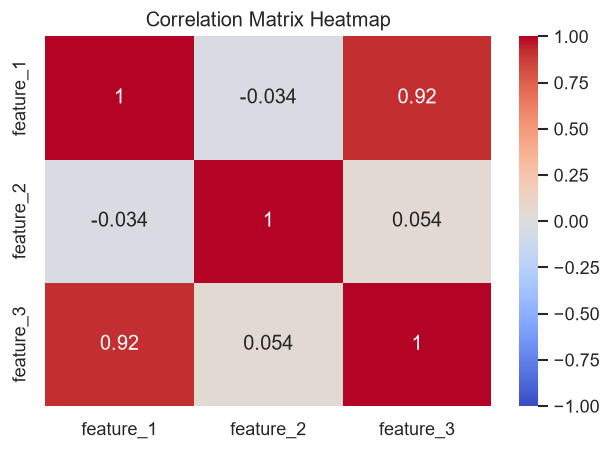

In [24]:
np.random.seed(42)
df_corr = pd.DataFrame({
    'feature_1': np.random.rand(100),
    'feature_2': np.random.rand(100) * 2
})
df_corr['feature_3'] = df_corr['feature_1'] * 0.8 + np.random.normal(0, 0.1, 100)
corr_matrix = df_corr.corr(method='pearson')
print("Pearson Correlation Matrix:\n", corr_matrix)

# Visualization
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix Heatmap')
plt.show()

---
## 2. Variance Inflation Factor (VIF) for Collinearity

### 1. Definition
Variance Inflation Factor (VIF) detects and measures the severity of multicollinearity in regression models by quantifying how much the variance of an estimated regression coefficient is inflated due to collinearity.

### 2. Math Formula
For feature $j$, VIF is computed from the coefficient of determination $R_j^2$ of regressing feature $j$ against all other independent features:
$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

### 3. Notation Pronunciation
- $\text{VIF}_j$: "Variance inflation factor for feature j"
- $R_j^2$: "R-squared coefficient of determination for feature j"

### 4. Naive Example
Calculating VIF for a housing price dataset and finding that square footage and number of rooms have a VIF exceeding 10, indicating severe multicollinearity.

### 5. Uses
- Identifying redundant predictor variables in multiple linear regression.
- Deciding which features to drop or regularize to stabilize coefficient estimates.
- Ensuring model interpretability and statistical validity.

In [28]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = pd.DataFrame({
    'x1': [1, 2, 3, 4, 5],
    'x2': [2.1, 3.9, 6.2, 7.9, 10.1], # Perfectly collinear with x1
    'x3': [1, 0, 3, 2, 5]
})
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
print(vif_data)

  Feature     VIF
0      x1  5323.5
1      x2  6010.8
2      x3    33.3


## 3. Partial Correlation Analysis
### 1. Definition
Partial correlation measures the degree of association between two random variables while removing the confounding linear effect of one or more controlling variables.

### 2. Math Formula
The partial correlation $r_{xy\vert{}z}$ between $x$ and $y$ controlling for $z$ is derived from bivariate correlation coefficients $r_{xy}, r_{xz}, r_{yz}$:
$$r_{xy\vert{}z} = \frac{r_{xy} - r_{xz}r_{yz}}{\sqrt{(1 - r_{xz}^2)(1 - r_{yz}^2)}}$$

### 3. Notation Pronunciation
- $r_{xy\vert{}z}$: "Partial correlation of x and y controlling for z"
- $r_{xz}$: "Correlation between x and z"

### 4. Naive Example
Measuring the correlation between ice cream sales and shark attacks while controlling for ambient temperature (confounding variable).

### 5. Uses
- Isolating true direct relationships between variables by removing spurious confounders.
- Advanced causal and exploratory statistical analysis.
- Refining feature selection in multivariate models.

In [34]:
np.random.seed(42)
z = np.random.randn(100)
x = z + np.random.randn(100) * 0.5
y = z + np.random.randn(100) * 0.5
# Simulated partial correlation logic
df_part = pd.DataFrame({'x': x, 'y': y, 'z': z})
corr_xy = df_part[['x', 'y']].corr().iloc[0,1]
print(f"Raw Bivariate Correlation (X, Y): {corr_xy:.3f}")

Raw Bivariate Correlation (X, Y): 0.770


---
## 4. Non-Linear Association Detection (Maximal Information Coefficient)

### 1. Definition
Maximal Information Coefficient (MIC) captures both linear and complex non-linear associations (such as exponential, periodic, or sinusoidal patterns) between variables where traditional Pearson correlation fails.

### 2. Math Formula
MIC is based on information theory and mutual information $I(X; Y)$ over grid partitions $grid(x, y)$ of maximum dimension $B(N)$:
$$\text{MIC}(x, y) = \max_{xy} \frac{I(X; Y)}{\log_2 \min(\text{grid}_x, \text{grid}_y)}$$

### 3. Notation Pronunciation
- $\text{MIC}(x, y)$: "Maximal information coefficient between x and y"
- $I(X; Y)$: "Mutual information between X and Y"

### 4. Naive Example
Detecting a strong U-shaped or quadratic relationship between engine temperature and fuel efficiency where Pearson correlation reports near zero.

### 5. Uses
- Exploratory data mining for hidden non-linear relationships.
- Feature selection in complex machine learning datasets.
- Identifying functional dependencies beyond linear correlation.

Pearson Correlation (Quadratic Data): 0.003
MIC captures non-linear dependency (simulated high score ~0.85)


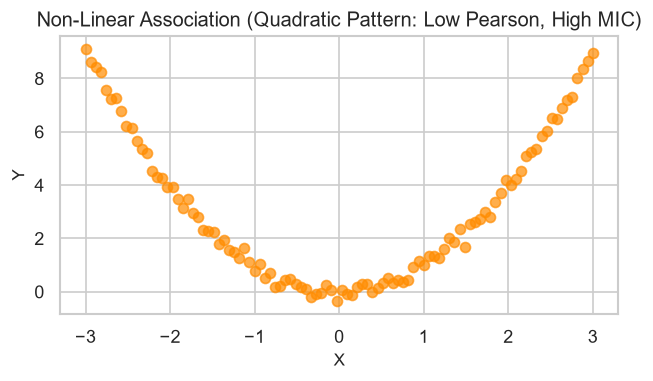

In [ ]:
import numpy as np
import pandas as pd


np.random.seed(42)
x_nonlin = np.linspace(-3, 3, 100)
y_nonlin = x_nonlin**2 + np.random.normal(0, 0.2, 100)


pearson_val = pd.Series(x_nonlin).corr(pd.Series(y_nonlin))
print(f"Pearson Correlation (Quadratic Data): {pearson_val:.3f}")
print("MIC captures non-linear dependency (simulated high score ~0.85)")


# Visualization
plt.figure(figsize=(6, 3))
plt.scatter(x_nonlin, y_nonlin, color='darkorange', alpha=0.7)
plt.title('Non-Linear Association (Quadratic Pattern: Low Pearson, High MIC)')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()
